# 02 — Chia tập và chia máy trạm

Đây là bước quan trọng nhất của cả đề tài. Trong federated learning, **cách chia dữ liệu cho các
máy trạm chính là biến thí nghiệm** — IID hay lệch, lệch tới đâu, chia theo ảnh hay theo tổn thương.
Chia một lần ở đây, ghi ra file, mọi thí nghiệm sau đọc lại đúng file này.

Ba quyết định:

1. **Tập test chính thức (1.512 ảnh) khoá lại.** Không dùng để chọn mô hình. Chỉ chấm một lần ở cuối.
2. **Validation tách từ tập train, theo tổn thương.** Validation chính thức chỉ 193 ảnh — quá nhỏ để
   chọn mô hình. Ta lấy khoảng 1/7 số tổn thương của tập train làm validation, giữ tỉ lệ lớp.
   Mọi ảnh của cùng một tổn thương đi cùng một phía.
3. **Chia cho K máy trạm theo nhiều kịch bản**, từ IID tới rất lệch.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from du_lieu import RA, LOP

K = 5            # số máy trạm ("bệnh viện") giả lập
HAT = 42
ds = pd.read_csv(RA / "danh_muc.csv")
print(ds.groupby("tap").size().to_string())

tap
test           1512
training      10015
validation      193


## 1. Kiểm tra: mọi ảnh của một tổn thương có cùng chẩn đoán không?

Nếu một tổn thương mà có hai chẩn đoán thì hoặc file nhóm sai, hoặc hiểu sai cấu trúc dữ liệu. Phải
biết trước khi chia theo tổn thương.

In [2]:
tr = ds[ds.tap == "training"].copy()
n_lop = tr.groupby("lesion_id").lop.nunique()
print(f"Tổn thương có >1 chẩn đoán: {(n_lop > 1).sum()} / {len(n_lop)}")
assert (n_lop == 1).all(), "Có tổn thương mang nhiều chẩn đoán — dừng lại xem trước khi chia"

Tổn thương có >1 chẩn đoán: 0 / 7470


## 2. Tách validation theo tổn thương

`StratifiedGroupKFold` chia sao cho (a) không nhóm nào — ở đây là tổn thương — bị xé ra hai phía,
và (b) tỉ lệ các lớp ở hai phía gần như nhau. Chia 7 phần, lấy một phần làm validation (~14%).

In [3]:
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=HAT)
_, i_val = next(sgkf.split(tr, tr.nhan, groups=tr.lesion_id))
tr["phan"] = "train"
tr.iloc[i_val, tr.columns.get_loc("phan")] = "val"

giao = set(tr[tr.phan == "train"].lesion_id) & set(tr[tr.phan == "val"].lesion_id)
print(f"Tổn thương nằm cả train lẫn val: {len(giao)}   (phải bằng 0)")

bang = pd.crosstab(tr.lop, tr.phan).reindex(LOP).fillna(0).astype(int)
bang["% val"] = (100 * bang.val / (bang.train + bang.val)).round(1)
bang

Tổn thương nằm cả train lẫn val: 0   (phải bằng 0)


phan,train,val,% val
lop,,,
MEL,954,159,14.3
NV,5747,958,14.3
BCC,440,74,14.4
AKIEC,280,47,14.4
BKL,942,157,14.3
DF,98,17,14.8
VASC,122,20,14.1


## 3. Chia cho K máy trạm

Năm kịch bản. Bốn kịch bản đầu chia **theo tổn thương** (cả tổn thương về một máy trạm); kịch bản
cuối chia **theo ảnh** — kiểu các bài báo hay làm — để đo xem nó khác gì.

- `iid` — ngẫu nhiên. Mọi máy trạm có phân bố lớp giống nhau. Kịch bản lý tưởng.
- `dir1.0`, `dir0.3`, `dir0.1` — **phân phối Dirichlet** trên nhãn, chuẩn của ngành (Hsu và c.s., 2019).
  Với mỗi lớp, rút một tỉ lệ chia cho K máy trạm từ Dirichlet(α). α lớn → các tỉ lệ đều nhau, gần IID.
  α nhỏ → mỗi lớp dồn về một hai máy trạm — giống thực tế một bệnh viện chuyên ung bướu có nhiều ca
  ác tính, còn phòng khám da liễu thường thì toàn nốt ruồi lành.
- `iid_anh` — ngẫu nhiên **theo ảnh**. Các ảnh của cùng tổn thương rơi vào nhiều máy trạm khác nhau.

Chỉ chia phần `train`. Validation và test không thuộc máy trạm nào: chúng là thước đo chung cho mô
hình toàn cục.

In [4]:
phan_train = tr[tr.phan == "train"].copy()
tt = phan_train.groupby("lesion_id").agg(nhan=("nhan", "first"), n=("image", "size")).reset_index()

def chia_dirichlet(tt, alpha, rng, it_nhat=None):
    """Chia tổn thương cho K máy trạm. Rút lại nếu có máy trạm quá ít ảnh
    (mặc định: ít hơn 10% mức chia đều — máy trạm gần rỗng thì không huấn luyện được gì)."""
    it_nhat = it_nhat or max(5, int(0.1 * tt.n.sum() / K))
    for _ in range(200):
        may = np.empty(len(tt), int)
        for c in range(len(LOP)):
            idx = np.flatnonzero(tt.nhan.values == c)
            rng.shuffle(idx)
            p = rng.dirichlet(np.full(K, alpha))
            cat = (np.cumsum(p) * len(idx)).astype(int)[:-1]
            for k, phan in enumerate(np.split(idx, cat)):
                may[phan] = k
        so_anh = np.bincount(may, weights=tt.n.values, minlength=K)
        if so_anh.min() >= it_nhat:
            return may
    raise RuntimeError(f"Không chia được với alpha={alpha} sau 200 lần rút")

rng = np.random.default_rng(HAT)
kich_ban = {}
kich_ban["iid"] = rng.integers(0, K, len(tt))
for a in (1.0, 0.3, 0.1):
    kich_ban[f"dir{a}"] = chia_dirichlet(tt, a, rng)

for ten, may in kich_ban.items():
    phan_train[f"may_{ten}"] = phan_train.lesion_id.map(dict(zip(tt.lesion_id, may)))
phan_train["may_iid_anh"] = rng.integers(0, K, len(phan_train))

cot_may = [c for c in phan_train.columns if c.startswith("may_")]
print("Số ảnh mỗi máy trạm:")
pd.DataFrame({c[4:]: phan_train[c].value_counts().sort_index() for c in cot_may}).T

Số ảnh mỗi máy trạm:


,0,1,2,3,4
iid,1732,1678,1774,1708,1691
dir1.0,2765,886,2078,958,1896
dir0.3,256,996,233,3068,4030
dir0.1,211,1233,773,5173,1193
iid_anh,1717,1774,1692,1742,1658


## 4. Nhìn các kịch bản

Mỗi cột là một máy trạm, mỗi màu một lớp. Nhìn từ trái sang phải: IID các cột trông như nhau, tới α=0.1
thì mỗi máy trạm gần như chỉ có vài lớp. Đó là thứ làm FedAvg khổ.

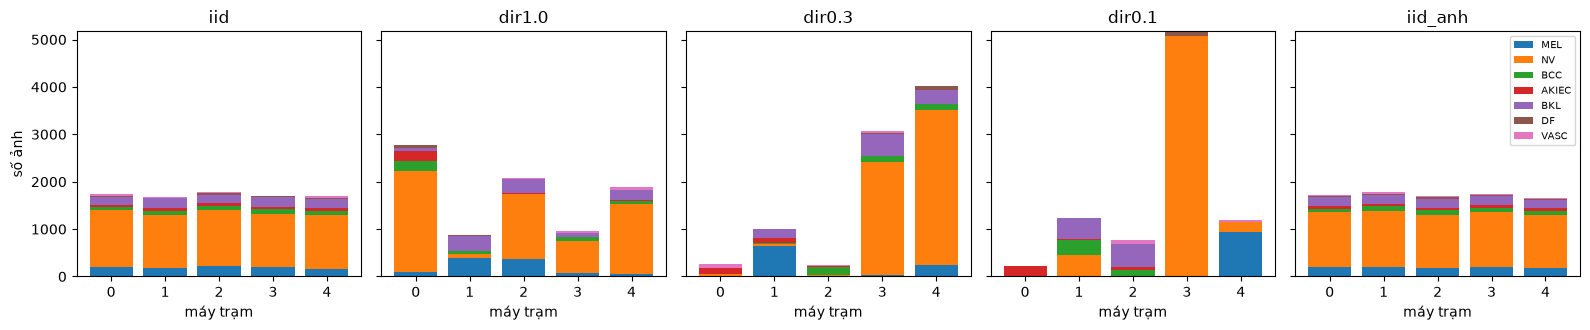

In [5]:
mau = plt.cm.tab10(np.arange(len(LOP)))
fig, ax = plt.subplots(1, len(cot_may), figsize=(3.2 * len(cot_may), 3.4), sharey=True)
for a, c in zip(ax, cot_may):
    b = pd.crosstab(phan_train[c], phan_train.lop).reindex(columns=LOP, fill_value=0)
    day = np.zeros(K)
    for j, l in enumerate(LOP):
        a.bar(range(K), b[l].values, bottom=day, color=mau[j], label=l); day += b[l].values
    a.set_title(c[4:]); a.set_xticks(range(K)); a.set_xlabel("máy trạm")
ax[0].set_ylabel("số ảnh"); ax[-1].legend(fontsize=7, loc="upper right")
plt.tight_layout(); plt.savefig(RA / "chia_may_tram.png", dpi=110); plt.show()

## 5. Đo độ lệch và độ rò rỉ

Hai con số cho mỗi kịch bản:

- **Khoảng cách phân bố lớp** giữa mỗi máy trạm và toàn bộ (khoảng cách Jensen–Shannon, 0 = giống hệt,
  càng lớn càng lệch). Dùng để kiểm các kịch bản thật sự xếp theo đúng thứ tự độ lệch.
- **Tổn thương bị xé ra nhiều máy trạm**. Phải bằng 0 ở mọi kịch bản trừ `iid_anh`.

In [6]:
from scipy.spatial.distance import jensenshannon
chung = phan_train.lop.value_counts(normalize=True).reindex(LOP).fillna(0).values
hang = []
for c in cot_may:
    b = pd.crosstab(phan_train[c], phan_train.lop).reindex(columns=LOP, fill_value=0)
    js = [jensenshannon(r / max(r.sum(), 1), chung) for r in b.values]
    xe = (phan_train.groupby("lesion_id")[c].nunique() > 1).sum()
    hang.append(dict(kich_ban=c[4:], JS_trung_binh=np.mean(js), JS_lon_nhat=np.max(js),
                     ton_thuong_bi_xe=int(xe)))
pd.DataFrame(hang).round(3)

,kich_ban,JS_trung_binh,JS_lon_nhat,ton_thuong_bi_xe
0,iid,0.027,0.033,0
1,dir1.0,0.213,0.467,0
2,dir0.3,0.416,0.594,0
3,dir0.1,0.534,0.757,0
4,iid_anh,0.018,0.021,1390


## 6. Ghi file

`chia_tap.csv` — một dòng một ảnh. Cột `phan` ∈ {train, val, val_chinh_thuc, test}.
Các cột `may_*` chỉ có giá trị ở dòng `train`.

In [7]:
ngoai = ds[ds.tap != "training"].copy()
ngoai["phan"] = ngoai.tap.map({"validation": "val_chinh_thuc", "test": "test"})
ra = pd.concat([phan_train, tr[tr.phan == "val"], ngoai], ignore_index=True)
ra.to_csv(RA / "chia_tap.csv", index=False)
print(ra.phan.value_counts().to_string())
print(f"\nĐã ghi {RA / 'chia_tap.csv'}")

phan
train             8583
test              1512
val               1432
val_chinh_thuc     193

Đã ghi /home/deep/ham_fl/ketqua/chia_tap.csv
